# FLO - BG/NBD ve Gamma-Gamma ile CLTV Tahmini

## İş problemi ve iki modelin rolü

FLO, satış ve pazarlama planlaması için mevcut müşterilerinin gelecekte sağlayacağı potansiyel değeri tahmin etmek istiyor. 


| Bileşen | Yanıtladığı soru | Çıktı |
|---|---|---|
| BG/NBD | Gelecekte kaç alışveriş yapmasını bekliyoruz? | Beklenen alışveriş sayısı |
| Gamma-Gamma | Bir alışverişte ne kadar harcamasını bekliyoruz? | Beklenen ortalama sepet tutarı |
| CLTV | Bu alışverişlerin bugünkü toplam değeri nedir? | İskontolu beklenen değer |




## CLTV Tahmini: BG/NBD ve Gamma-Gamma

### 1. BG/NBD: Beklenen Alışveriş Sayısı

**BG/NBD (Beta-Geometric / Negative Binomial Distribution)**,
müşterinin geçmiş alışverişlerinden yararlanarak belirli bir gelecek
dönemdeki **beklenen işlem sayısını** tahmin eder.

Özellikle müşterinin ayrıldığını doğrudan gözlemleyemediğimiz,
abonelik gerektirmeyen perakende gibi alanlarda kullanılır:
**Müşteri bizi bıraktı mı, yoksa iki alışverişi arasındaki süre mi uzadı?**

Model iki süreci birlikte ele alır:

- **NBD kısmı:** Müşteri aktifken alışverişler Poisson süreciyle;
  müşteriler arasındaki alışveriş hızı farklılıkları Gamma dağılımıyla
  modellenir. Poisson–Gamma birleşimi negatif binom dağılımını verir.
- **BG kısmı:** Müşterinin her alışverişten sonra kalıcı olarak
  pasifleşebileceği varsayılır. Bu olasılık müşteriler arasında
  Beta dağılımıyla değişir.

Inputs:

| Değişken | Anlamı |
|---|---|
| `frequency` | İlk alışverişten sonraki tekrar alışveriş sayısı |
| `recency` | İlk alışveriş ile son alışveriş arasındaki süre |
| `T` | İlk alışveriş ile gözlem dönemi sonu arasındaki süre |

-------------------------------------------------

> Buradaki `recency`, klasik RFM’deki “son alışverişten bugüne geçen süre”
> değildir. O süre `T - recency` ile bulunur.

### 2. Gamma-Gamma: Beklenen Ortalama Alışveriş Tutarı

Gamma-Gamma, müşterinin gelecekteki **işlem başına ortalama harcamasını**
tahmin eder. Hem aynı müşterinin alışveriş tutarlarındaki değişkenliği
hem de müşteriler arasındaki harcama farklılıklarını dikkate alır.

Inputs: `frequency` ve `monetary_value_avg` 
**Monetary, toplam harcama değil, tekrar alışverişlerin ortalama tutarıdır.**

- Eğitimde tekrar alışverişi bulunan ve parasal değeri pozitif müşteriler kullanılır.
- Temel varsayım, alışveriş sıklığı ile müşterinin ortalama işlem değerinin
  bağımsız olmasıdır. Düşük korelasyon bir ön kontroldür.


### İki Model Nasıl Birleşir?


$$\text{Beklenen değer}\approx\text{Beklenen alışveriş sayısı}\times\text{Beklenen sepet tutarı}$$

----------------------------------------

## Kurulum ve kütüphaneler

`lifetimes`, BG/NBD ve Gamma-Gamma modellerini sağlar. 


In [83]:
# %pip install lifetimes pandas

import datetime as dt
import pandas as pd
from IPython.display import display
from lifetimes import BetaGeoFitter, GammaGammaFitter

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: "%.3f" % x)
pd.set_option("display.float_format",
    lambda x: f"{x:,.2f}".replace(",", "_").replace(".", ",").replace("_", "."))


## Ek Bilgi: CLTV için başka hangi yöntemler kullanılabilir?


| Yöntem | Temel yaklaşım |
|---|---|
| Pareto/NBD | BG/NBD gibi alışveriş ve müşteri kaybını modeller; müşterinin herhangi bir zamanda kalıcı olarak ayrılabileceğini varsayar. Buy Till You Die |
| Bayesçi CLTV | Parametrelerin belirsizliğini de hesaplayarak tahminler için belirsizlik aralıkları üretir. Domain knowledge varsa |
| Makine öğrenmesi | Geçmiş müşteri özelliklerinden gelecek dönemin toplam harcamasını doğrudan tahmin edebilir. |


## Ek Bilgi: Kullanılabilecek kütüphaneler

| Kütüphane | Ne için kullanılır? |
|---|---|
| `lifetimes` | BG/NBD, Pareto/NBD ve Gamma-Gamma gibi müşteri davranışı modelleri. |
| `PyMC-Marketing` | Bayesçi CLTV modelleri ve belirsizlik analizi. |
| `LightGBM` | Gelecek dönem alışveriş adedi veya harcama tahmini için makine öğrenmesi modelleri. |
| `scikit-survival` | Olay gerçekleşene kadar geçen süreyi modelleyen survival yöntemleri. |
| `Optuna` | Hiperparametre aramasını otomatikleştirme. |


## Görev 1 — Veriyi hazırlama

### Adım 1: Veriyi oku ve ilk kontrolleri yap


In [84]:
def check_df(dataframe):
    print("Veri boyutu:", dataframe.shape)

    print("\nİlk 5 gözlem:")
    display(dataframe.head())

    print("\nVeri tipleri ve doluluk bilgisi:")
    dataframe.info()

    print("\nSayısal değişkenlerin özeti:")
    display(dataframe.describe().T)

    print("\nEksik değerler:")
    display(dataframe.isnull().sum().to_frame("eksik_deger"))


df1 = pd.read_csv("flo_data_20k.csv")
df = df1.copy()

check_df(df)


Veri boyutu: (19945, 12)

İlk 5 gözlem:


,master_id,order_channel,last_order_channel,first_order_date,last_order_date,last_order_date_online,last_order_date_offline,order_num_total_ever_online,order_num_total_ever_offline,customer_value_total_ever_offline,customer_value_total_ever_online,interested_in_categories_12
0,cc294636-19f0-11eb-8d74-000d3a38a36f,Android App,Offline,2020-10-30,2021-02-26,2021-02-21,2021-02-26,"4,00","1,00","139,99","799,38",[KADIN]
1,f431bd5a-ab7b-11e9-a2fc-000d3a38a36f,Android App,Mobile,2017-02-08,2021-02-16,2021-02-16,2020-01-10,"19,00","2,00","159,97","1.853,58","[ERKEK, COCUK, KADIN, AKTIFSPOR]"
2,69b69676-1a40-11ea-941b-000d3a38a36f,Android App,Android App,2019-11-27,2020-11-27,2020-11-27,2019-12-01,"3,00","2,00","189,97","395,35","[ERKEK, KADIN]"
3,1854e56c-491f-11eb-806e-000d3a38a36f,Android App,Android App,2021-01-06,2021-01-17,2021-01-17,2021-01-06,"1,00","1,00","39,99","81,98","[AKTIFCOCUK, COCUK]"
4,d6ea1074-f1f5-11e9-9346-000d3a38a36f,Desktop,Desktop,2019-08-03,2021-03-07,2021-03-07,2019-08-03,"1,00","1,00","49,99","159,99",[AKTIFSPOR]



Veri tipleri ve doluluk bilgisi:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19945 entries, 0 to 19944
Data columns (total 12 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   master_id                          19945 non-null  object 
 1   order_channel                      19945 non-null  object 
 2   last_order_channel                 19945 non-null  object 
 3   first_order_date                   19945 non-null  object 
 4   last_order_date                    19945 non-null  object 
 5   last_order_date_online             19945 non-null  object 
 6   last_order_date_offline            19945 non-null  object 
 7   order_num_total_ever_online        19945 non-null  float64
 8   order_num_total_ever_offline       19945 non-null  float64
 9   customer_value_total_ever_offline  19945 non-null  float64
 10  customer_value_total_ever_online   19945 non-null  float64
 11  interested_in_catego

,count,mean,std,min,25%,50%,75%,max
order_num_total_ever_online,"19.945,00","3,11","4,23","1,00","1,00","2,00","4,00","200,00"
order_num_total_ever_offline,"19.945,00","1,91","2,06","1,00","1,00","1,00","2,00","109,00"
customer_value_total_ever_offline,"19.945,00","253,92","301,53","10,00","99,99","179,98","319,97","18.119,14"
customer_value_total_ever_online,"19.945,00","497,32","832,60","12,99","149,98","286,46","578,44","45.220,13"



Eksik değerler:


,eksik_deger
master_id,0
order_channel,0
last_order_channel,0
first_order_date,0
last_order_date,0
last_order_date_online,0
last_order_date_offline,0
order_num_total_ever_online,0
order_num_total_ever_offline,0
customer_value_total_ever_offline,0


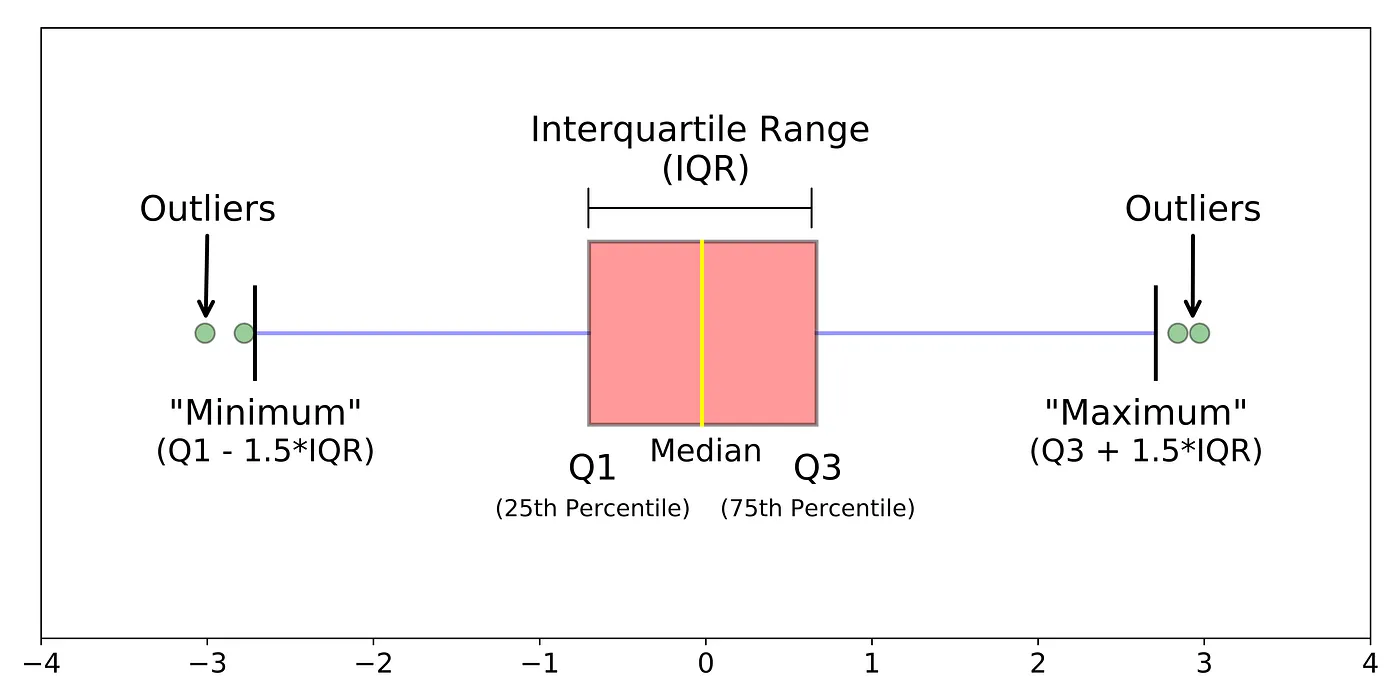

### Adım 2: Aykırı değerleri baskılama fonksiyonları





$$R=Q_{0.99}-Q_{0.01}$$
$$L=Q_{0.01}-1.5R,\qquad U=Q_{0.99}+1.5R$$



In [85]:
def outlier_thresholds(dataframe, variable):
    quartile1 = dataframe[variable].quantile(0.01)
    quartile3 = dataframe[variable].quantile(0.99)
    interquantile_range = quartile3 - quartile1
    low_limit = quartile1 - 1.5 * interquantile_range
    up_limit = quartile3 + 1.5 * interquantile_range
    return round(low_limit), round(up_limit)     # CLTV hesaplanırken frequency değerleri integer olmalıdır,round(). 


def replace_with_thresholds(dataframe, variable):
    low_limit, up_limit = outlier_thresholds(dataframe, variable)
    dataframe.loc[dataframe[variable] < low_limit, variable] = low_limit
    dataframe.loc[dataframe[variable] > up_limit, variable] = up_limit


### Adım 3: Sayısal değişkende aykırı değerleri baskılama, fonksiyonları çağıralım

"order_num_total_ever_online",
"order_num_total_ever_offline",
"customer_value_total_ever_offline",
"customer_value_total_ever_online" değişkenlerinin aykırı değerlerine bakıyoruz.

In [86]:
outlier_cols = [
    "order_num_total_ever_online",
    "order_num_total_ever_offline",
    "customer_value_total_ever_offline",
    "customer_value_total_ever_online",
]
order_cols = ["order_num_total_ever_online", "order_num_total_ever_offline"]

for col in outlier_cols:
    replace_with_thresholds(df, col)

df[order_cols] = df[order_cols].astype(int)
display(df[outlier_cols].describe().T)


,count,mean,std,min,25%,50%,75%,max
order_num_total_ever_online,"19.945,00","3,09","3,81","1,00","1,00","2,00","4,00","48,00"
order_num_total_ever_offline,"19.945,00","1,89","1,43","1,00","1,00","1,00","2,00","16,00"
customer_value_total_ever_offline,"19.945,00","251,92","251,02","10,00","99,99","179,98","319,97","3.020,00"
customer_value_total_ever_online,"19.945,00","489,71","632,61","12,99","149,98","286,46","578,44","7.800,00"


Baskılama fonksiyonlarından önce: 

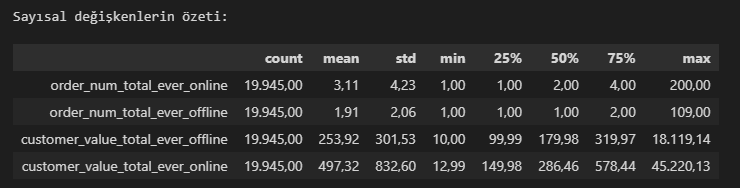

### Adım 4: Toplam alışveriş sayısı ve toplam harcama değişkenlerini oluşturma

Omnichannel müşteriyi kanallara bölmeden değerlendiririz. Her müşteri için toplam adet ve toplam harcama oluştururuz:

$$n=n_{online}+n_{offline},\qquad V=V_{online}+V_{offline}$$



In [87]:
df["total_order_num"] = df["order_num_total_ever_online"] + df["order_num_total_ever_offline"]
df["total_customer_value"] = df["customer_value_total_ever_online"] + df["customer_value_total_ever_offline"]

display(df[["master_id", "total_order_num", "total_customer_value"]].head())


,master_id,total_order_num,total_customer_value
0,cc294636-19f0-11eb-8d74-000d3a38a36f,5,"939,37"
1,f431bd5a-ab7b-11e9-a2fc-000d3a38a36f,21,"2.013,55"
2,69b69676-1a40-11ea-941b-000d3a38a36f,5,"585,32"
3,1854e56c-491f-11eb-806e-000d3a38a36f,2,"121,97"
4,d6ea1074-f1f5-11e9-9346-000d3a38a36f,2,"209,98"


### Adım 5: Tarih sütunlarını dtype datetime olarak dönüştür

İki tarih arasındaki gün sayısını hesaplayabilmek için `pd.to_datetime()` ile tarih tipine dönüştürürüz. Kaynak kod gibi adında `date` geçen sütunları seçiyoruz.


In [88]:
date_cols = [col for col in df.columns if "date" in col]

for col in date_cols:
    df[col] = pd.to_datetime(df[col])

print(df[date_cols].dtypes)


first_order_date           datetime64[ns]
last_order_date            datetime64[ns]
last_order_date_online     datetime64[ns]
last_order_date_offline    datetime64[ns]
dtype: object


## Görev 2 — CLTV veri yapısını oluşturma
### Adım 1: Analiz tarihini belirle

Veri setindeki en son alışveriş tarihinin **2 gün sonrasını** kullanıyoruz. Analiz tarihi, müşterinin ne kadar süredir gözlendiğini hesapladığımız referans noktasıdır.


In [89]:
analysis_date_start = df["first_order_date"].min()
analysis_date = df["last_order_date"].max() + dt.timedelta(days=2)
analysis_date_finish = df["last_order_date"].max()

print("Analiz tarihi başlangıcı:", analysis_date_start)
print("Analiz tarihi bitiş:", analysis_date_finish)
print("")
print("Analiz tarihi :", analysis_date)

Analiz tarihi başlangıcı: 2013-01-14 00:00:00
Analiz tarihi bitiş: 2021-05-30 00:00:00

Analiz tarihi : 2021-06-01 00:00:00


### Adım 2: Modellerin kullanacağı müşteri özetini oluştur

customer_id, recency_cltv_weekly, T_weekly, frequency ve monetary_cltv_avg değerlerini oluşturalım

| Değişken | Hesaplama | Anlamı |
|---|---|---|
| `customer_id` | `master_id` | Müşteri kimliği |
| `recency_cltv_weekly` | (Son alışveriş − ilk alışveriş) / 7 | İlk ve son alışveriş arasındaki hafta |
| `T_weekly` | (Analiz tarihi − ilk alışveriş) / 7 | Müşterinin gözlem süresi, hafta |
| `frequency` | Toplam alışveriş sayısı | Bu case'in kullandığı adet tanımı |
| `monetary_cltv_avg` | Toplam harcama / toplam alışveriş sayısı | Geçmiş ortalama sepet tutarı |

**Recency ayrımı:** RFM'de recency son alışverişten bugüne geçen süredir. Burada ise **ilk ve son alışveriş arasındaki süredir**. Son alışverişten analize kadar geçen süre `T_weekly − recency_cltv_weekly` ile bulunur.


In [90]:
cltv = pd.DataFrame()
cltv["customer_id"] = df["master_id"]
cltv["recency_cltv_weekly"] = (df["last_order_date"] - df["first_order_date"]).dt.days / 7
cltv["T_weekly"] = (analysis_date - df["first_order_date"]).dt.days / 7
cltv["frequency"] = df["total_order_num"].astype(int)  # Kaynak case'in toplam adet tanımı
cltv["monetary_cltv_avg"] = df["total_customer_value"] / df["total_order_num"]


# BG/NBD ve Gamma-Gamma için frequency > 1 olmalıdır.
cltv = cltv[(cltv["frequency"] > 1) & (cltv["monetary_cltv_avg"] > 0)].copy()
cltv.reset_index(drop=True, inplace=True)

display(cltv.head())
display(cltv.describe().T)

,customer_id,recency_cltv_weekly,T_weekly,frequency,monetary_cltv_avg
0,cc294636-19f0-11eb-8d74-000d3a38a36f,"17,00","30,57",5,"187,87"
1,f431bd5a-ab7b-11e9-a2fc-000d3a38a36f,"209,86","224,86",21,"95,88"
2,69b69676-1a40-11ea-941b-000d3a38a36f,"52,29","78,86",5,"117,06"
3,1854e56c-491f-11eb-806e-000d3a38a36f,"1,57","20,86",2,"60,98"
4,d6ea1074-f1f5-11e9-9346-000d3a38a36f,"83,14","95,43",2,"104,99"


,count,mean,std,min,25%,50%,75%,max
recency_cltv_weekly,"19.945,00","95,26","74,59","0,00","50,43","76,57","109,43","433,43"
T_weekly,"19.945,00","114,47","74,77","0,71","73,86","93,00","119,43","437,14"
frequency,"19.945,00","4,98","4,12","2,00","3,00","4,00","6,00","57,00"
monetary_cltv_avg,"19.945,00","152,10","73,52","22,49","103,65","136,91","182,45","1.401,80"


## Görev 3 — Modelleri kurma ve CLTV hesaplama
### Adım 1: BG/NBD modelini kur

BG/NBD, müşterinin alışveriş geçmişinden **gelecekte beklenen alışveriş sayısını** tahmin eder.

Inputs: **frequency, recency ve T**. 

- `fit()`: Ortak model parametrelerini müşteri geçmişlerinden öğrenir.
- `predict()`: Öğrenilen modelle belirli bir gelecek süre için tahmin üretir.
- `penalizer_coef`: Çok uç parametrelere ceza ekleyen düzenlileştirme katsayısıdır; büyük olması mutlaka daha iyi değildir.

Kaynak Python dosyasındaki BG/NBD katsayısını (`0.001`) koruyoruz.


In [91]:
bgf = BetaGeoFitter(penalizer_coef=0.001)

bgf.fit(
    cltv["frequency"],
    cltv["recency_cltv_weekly"], 
    cltv["T_weekly"])


<lifetimes.BetaGeoFitter: fitted with 19945 subjects, a: 0.00, alpha: 76.17, b: 0.00, r: 3.66>



Süre girdileri haftalık olduğu için `predict()` içindeki süre de haftadır. Kaynak çözümün **1 ay ≈ 4 hafta** yaklaşımıyla 3 ay için 12, 6 ay için 24 hafta kullanıyoruz.

#### 3 ay için beklenen alışveriş sayıları

In [92]:
cltv["exp_sales_3_month"] = bgf.predict(
    4 * 3, cltv["frequency"], cltv["recency_cltv_weekly"], cltv["T_weekly"]
)

print("3 ayda en çok alışveriş beklenen 10 müşteri:")
display(cltv.sort_values("exp_sales_3_month", ascending=False).head(10))

3 ayda en çok alışveriş beklenen 10 müşteri:


,customer_id,recency_cltv_weekly,T_weekly,frequency,monetary_cltv_avg,exp_sales_3_month
7330,a4d534a2-5b1b-11eb-8dbd-000d3a38a36f,"62,71","67,29",52,"166,22","4,66"
15611,4a7e875e-e6ce-11ea-8f44-000d3a38a36f,"39,71","40,00",29,"165,30","3,37"
8328,1902bf80-0035-11eb-8341-000d3a38a36f,"28,86","33,29",25,"97,44","3,14"
19538,55d54d9e-8ac7-11ea-8ec0-000d3a38a36f,"52,57","58,71",31,"228,53","3,08"
14373,f00ad516-c4f4-11ea-98f7-000d3a38a36f,"38,00","46,43",27,"141,35","3,00"
10489,7af5cd16-b100-11e9-9757-000d3a38a36f,"103,14","111,86",43,"157,11","2,98"
4315,d5ef8058-a5c6-11e9-a2fc-000d3a38a36f,"133,14","147,14",49,"161,85","2,83"
6756,27310582-6362-11ea-a6dc-000d3a38a36f,"62,71","64,14",29,"168,88","2,79"
6666,53fe00d4-7b7a-11eb-960b-000d3a38a36f,"9,71","13,00",17,"259,87","2,78"
10536,e143b6fa-d6f8-11e9-93bc-000d3a38a36f,"104,57","113,43",40,"176,20","2,76"


#### 6 ay için beklenen alışveriş sayıları

In [93]:
cltv["exp_sales_6_month"] = bgf.predict(
    4 * 6, cltv["frequency"], cltv["recency_cltv_weekly"], cltv["T_weekly"]
)

print("6 ayda en çok alışveriş beklenen 10 müşteri:")
display(cltv.sort_values("exp_sales_6_month", ascending=False).head(10))

6 ayda en çok alışveriş beklenen 10 müşteri:


,customer_id,recency_cltv_weekly,T_weekly,frequency,monetary_cltv_avg,exp_sales_3_month,exp_sales_6_month
7330,a4d534a2-5b1b-11eb-8dbd-000d3a38a36f,"62,71","67,29",52,"166,22","4,66","9,31"
15611,4a7e875e-e6ce-11ea-8f44-000d3a38a36f,"39,71","40,00",29,"165,30","3,37","6,75"
8328,1902bf80-0035-11eb-8341-000d3a38a36f,"28,86","33,29",25,"97,44","3,14","6,28"
19538,55d54d9e-8ac7-11ea-8ec0-000d3a38a36f,"52,57","58,71",31,"228,53","3,08","6,17"
14373,f00ad516-c4f4-11ea-98f7-000d3a38a36f,"38,00","46,43",27,"141,35","3,00","6,00"
10489,7af5cd16-b100-11e9-9757-000d3a38a36f,"103,14","111,86",43,"157,11","2,98","5,96"
4315,d5ef8058-a5c6-11e9-a2fc-000d3a38a36f,"133,14","147,14",49,"161,85","2,83","5,66"
6756,27310582-6362-11ea-a6dc-000d3a38a36f,"62,71","64,14",29,"168,88","2,79","5,59"
6666,53fe00d4-7b7a-11eb-960b-000d3a38a36f,"9,71","13,00",17,"259,87","2,78","5,56"
10536,e143b6fa-d6f8-11e9-93bc-000d3a38a36f,"104,57","113,43",40,"176,20","2,76","5,53"


### Adım 2: Gamma-Gamma modelini kur

Gamma-Gamma, **işlem başına beklenen ortalama tutarı** tahmin eder. 

Girdiler `frequency` ve `monetary_cltv_avg` sütunlarıdır. 


In [94]:
ggf = GammaGammaFitter(penalizer_coef=0.01)
ggf.fit(cltv["frequency"], cltv["monetary_cltv_avg"])

# Müşteri beklenen ortalama değerini tahminleyelim
cltv["exp_average_value"] = ggf.conditional_expected_average_profit(
    cltv["frequency"], 
    cltv["monetary_cltv_avg"]
)

display(cltv.sort_values("exp_average_value", ascending=False).head(10))


,customer_id,recency_cltv_weekly,T_weekly,frequency,monetary_cltv_avg,exp_sales_3_month,exp_sales_6_month,exp_average_value
9055,47a642fe-975b-11eb-8c2a-000d3a38a36f,"2,86","7,86",4,"1.401,80","1,09","2,19","1.449,06"
17323,f59053e2-a503-11e9-a2fc-000d3a38a36f,"51,71","101,00",7,"1.106,47","0,72","1,44","1.127,61"
15516,9083981a-f59e-11e9-841e-000d3a38a36f,"63,57","83,86",4,"1.090,36","0,57","1,15","1.127,35"
6402,851de3b4-8f0c-11eb-8cb8-000d3a38a36f,"8,29","9,43",2,"862,69","0,79","1,59","923,68"
16410,6fecd6c8-261a-11ea-8e1c-000d3a38a36f,"57,00","94,86",2,"859,58","0,40","0,79","920,36"
1853,f02473b0-43c3-11eb-806e-000d3a38a36f,"17,29","23,14",2,"835,88","0,68","1,37","895,04"
7936,ae4ce104-dbd4-11ea-8757-000d3a38a36f,"3,71","42,00",3,"844,35","0,68","1,35","883,29"
9738,3a27b334-dff4-11ea-acaa-000d3a38a36f,"40,00","41,14",3,"837,06","0,68","1,36","875,67"
12828,0c24fc44-2ac8-11ea-9d27-000d3a38a36f,"68,00","84,29",2,"779,26","0,42","0,85","834,57"
2291,26ac1432-1dd3-11ea-8bf2-000d3a38a36f,"55,71","97,71",3,"780,56","0,46","0,92","816,66"


Not: Biz harcama tutarlarını verdiğimiz için burada hesaplanan değer alışveriş başına beklenen ciro tutarıdır.

### Adım 3: 6 aylık CLTV'yi hesapla ve dataframe'e ekle

In [95]:
cltv["cltv"] = ggf.customer_lifetime_value(
    bgf,
    cltv["frequency"],
    cltv["recency_cltv_weekly"],
    cltv["T_weekly"],
    cltv["monetary_cltv_avg"],
    time=6,
    freq="W",
    discount_rate=0.01,
)

print("6 aylık CLTV değeri en yüksek 5 müşteri:")
display(cltv.sort_values("cltv", ascending=False).head(5))

display(cltv.sort_values("cltv", ascending=False).tail(5))


6 aylık CLTV değeri en yüksek 5 müşteri:


,customer_id,recency_cltv_weekly,T_weekly,frequency,monetary_cltv_avg,exp_sales_3_month,exp_sales_6_month,exp_average_value,cltv
9055,47a642fe-975b-11eb-8c2a-000d3a38a36f,"2,86","7,86",4,"1.401,80","1,09","2,19","1.449,06","3.327,78"
13880,7137a5c0-7aad-11ea-8f20-000d3a38a36f,"6,14","13,14",11,"758,09","1,97","3,94","767,36","3.172,39"
17323,f59053e2-a503-11e9-a2fc-000d3a38a36f,"51,71","101,00",7,"1.106,47","0,72","1,44","1.127,61","1.708,98"
12438,625f40a2-5bd2-11ea-98b0-000d3a38a36f,"74,29","74,57",16,"501,87","1,57","3,13","506,17","1.662,61"
7330,a4d534a2-5b1b-11eb-8dbd-000d3a38a36f,"62,71","67,29",52,"166,22","4,66","9,31","166,71","1.628,89"


,customer_id,recency_cltv_weekly,T_weekly,frequency,monetary_cltv_avg,exp_sales_3_month,exp_sales_6_month,exp_average_value,cltv
2641,f7b3612e-a6ce-11e9-a2fc-000d3a38a36f,"334,57","361,29",4,"34,99","0,21","0,42","37,20","16,41"
11232,f486e45e-a691-11e9-a2fc-000d3a38a36f,"350,57","378,14",2,"45,24","0,15","0,30","50,50","15,85"
6963,7e0928c6-a6e3-11e9-a2fc-000d3a38a36f,"342,00","352,71",4,"32,94","0,21","0,43","35,07","15,78"
27,c1f8f878-9f35-11e9-9897-000d3a38a36f,"404,00","417,14",4,"32,72","0,19","0,37","34,85","13,63"
1710,08b95b62-a987-11e9-a2fc-000d3a38a36f,"226,57","232,43",2,"22,49","0,22","0,44","26,20","12,11"


## Görev 4 — CLTV'ye göre segment oluşturma
### Adım 1: Müşterileri dört segmente ayır

| Segment | Sıralamadaki yeri |
|---|---|
| A | En yüksek CLTV'li %25 |
| B | Sonraki %25 |
| C | Sonraki %25 |
| D | En düşük CLTV'li %25 |

`qcut` gözlem sayısını yaklaşık dengeler; `cut` ise değer aralığını böler.


In [100]:
cltv["cltv_segment"] = pd.qcut(cltv["cltv"], 4, labels=["D", "C", "B", "A"])

print("\nSegmentlere göre ilk ve son gözlemler:")
display(cltv.sort_values("cltv", ascending=False).head(5))
display(cltv.sort_values("cltv", ascending=False).tail(5))



Segmentlere göre ilk ve son gözlemler:


,customer_id,recency_cltv_weekly,T_weekly,frequency,monetary_cltv_avg,exp_sales_3_month,exp_sales_6_month,exp_average_value,cltv,cltv_segment
9055,47a642fe-975b-11eb-8c2a-000d3a38a36f,"2,86","7,86",4,"1.401,80","1,09","2,19","1.449,06","3.327,78",A
13880,7137a5c0-7aad-11ea-8f20-000d3a38a36f,"6,14","13,14",11,"758,09","1,97","3,94","767,36","3.172,39",A
17323,f59053e2-a503-11e9-a2fc-000d3a38a36f,"51,71","101,00",7,"1.106,47","0,72","1,44","1.127,61","1.708,98",A
12438,625f40a2-5bd2-11ea-98b0-000d3a38a36f,"74,29","74,57",16,"501,87","1,57","3,13","506,17","1.662,61",A
7330,a4d534a2-5b1b-11eb-8dbd-000d3a38a36f,"62,71","67,29",52,"166,22","4,66","9,31","166,71","1.628,89",A


,customer_id,recency_cltv_weekly,T_weekly,frequency,monetary_cltv_avg,exp_sales_3_month,exp_sales_6_month,exp_average_value,cltv,cltv_segment
2641,f7b3612e-a6ce-11e9-a2fc-000d3a38a36f,"334,57","361,29",4,"34,99","0,21","0,42","37,20","16,41",D
11232,f486e45e-a691-11e9-a2fc-000d3a38a36f,"350,57","378,14",2,"45,24","0,15","0,30","50,50","15,85",D
6963,7e0928c6-a6e3-11e9-a2fc-000d3a38a36f,"342,00","352,71",4,"32,94","0,21","0,43","35,07","15,78",D
27,c1f8f878-9f35-11e9-9897-000d3a38a36f,"404,00","417,14",4,"32,72","0,19","0,37","34,85","13,63",D
1710,08b95b62-a987-11e9-a2fc-000d3a38a36f,"226,57","232,43",2,"22,49","0,22","0,44","26,20","12,11",D


In [97]:
segment_summary = cltv.groupby("cltv_segment", observed=True).agg({
    "customer_id": "count",
    "recency_cltv_weekly": "mean",
    "T_weekly": "mean",
    "frequency": "mean",
    "monetary_cltv_avg": "mean",
    "exp_sales_3_month": "mean",
    "exp_sales_6_month": "mean",
    "exp_average_value": "mean",
    "cltv": "mean",
}).sort_values("cltv", ascending=False)

display(segment_summary)


,customer_id,recency_cltv_weekly,T_weekly,frequency,monetary_cltv_avg,exp_sales_3_month,exp_sales_6_month,exp_average_value,cltv
cltv_segment,,,,,,,,,
A,4986,"67,43","82,55","6,65","228,83","0,77","1,55","238,02","362,32"
B,4986,"81,99","100,33","5,09","160,64","0,60","1,20","168,00","199,53"
C,4986,"92,63","112,82","4,40","125,79","0,53","1,05","132,25","138,31"
D,4987,"139,00","162,18","3,77","93,15","0,41","0,82","98,69","80,34"


### Segment tablosunu nasıl yorumlarız?

### İki segment için 6 aylık aksiyon önerisi

| Segment | Öneri | İzlenecek sonuç |
|---|---|---|
| A | İlk ay kategori tercihlerine göre kişiselleştirilmiş iletişim kur; sonraki aylarda sadakat avantajları ve yeni koleksiyonlara erken erişim sun. | Kontrol grubuna göre tekrar alışveriş, elde tutma ve ek katkı kârı |
| D | Küçük bütçeli bir grupla e-posta/SMS hatırlatma veya yeniden aktivasyon denemesi yap; ilk sonuçlara göre kalan aylarda kapsamı ayarla. | Ek dönüşüm, müşteri başına maliyet ve kampanyanın ek katkı kârı |

D segmenti otomatik olarak kaybedilmiş müşteri demek değildir; küçük sepetle düzenli alışveriş yapanlar da burada olabilir.

### Sonuçları kaydet

In [98]:
# cltv.to_csv("flo_cltv_prediction.csv", index=False)
# segment_summary.to_csv("flo_cltv_segment_summary.csv")


## Bonus — Süreci fonksiyonlaştırma


In [102]:
def create_cltv_prediction(dataframe, month=6):
    """
    FLO veri seti için BG/NBD + Gamma-Gamma modelleriyle CLTV hesaplar.
    """
    dataframe = dataframe.copy()

    # Aykırı değerleri baskılama
    for col in outlier_cols:
        replace_with_thresholds(dataframe, col)

    dataframe[order_cols] = dataframe[order_cols].astype(int)

    # Toplam alışveriş ve toplam değer
    dataframe["total_order_num"] = (
        dataframe["order_num_total_ever_online"] + dataframe["order_num_total_ever_offline"]
    )
    dataframe["total_customer_value"] = (
        dataframe["customer_value_total_ever_online"] + dataframe["customer_value_total_ever_offline"]
    )

    # Tarih dönüşümü
    date_cols_func = [col for col in dataframe.columns if "date" in col]
    for col in date_cols_func:
        dataframe[col] = pd.to_datetime(dataframe[col])

    analysis_date_func = dataframe["last_order_date"].max() + dt.timedelta(days=2)

    # CLTV veri yapısı
    cltv_final = pd.DataFrame()
    cltv_final["customer_id"] = dataframe["master_id"]
    cltv_final["recency_cltv_weekly"] = (
        dataframe["last_order_date"] - dataframe["first_order_date"]
    ).dt.days / 7
    cltv_final["T_weekly"] = (analysis_date_func - dataframe["first_order_date"]).dt.days / 7
    cltv_final["frequency"] = dataframe["total_order_num"].astype(int)
    cltv_final["monetary_cltv_avg"] = (
        dataframe["total_customer_value"] / dataframe["total_order_num"]
    )

    cltv_final = cltv_final[
        (cltv_final["frequency"] > 1) & (cltv_final["monetary_cltv_avg"] > 0)
    ]
    cltv_final.reset_index(drop=True, inplace=True)

    # BG/NBD
    bgf_model = BetaGeoFitter(penalizer_coef=0.001)
    bgf_model.fit(
        cltv_final["frequency"],
        cltv_final["recency_cltv_weekly"],
        cltv_final["T_weekly"],
    )

    cltv_final["exp_sales_3_month"] = bgf_model.predict(
        4 * 3,
        cltv_final["frequency"],
        cltv_final["recency_cltv_weekly"],
        cltv_final["T_weekly"],
    )
    cltv_final["exp_sales_6_month"] = bgf_model.predict(
        4 * 6,
        cltv_final["frequency"],
        cltv_final["recency_cltv_weekly"],
        cltv_final["T_weekly"],
    )

    # Gamma-Gamma
    ggf_model = GammaGammaFitter(penalizer_coef=0.01)
    ggf_model.fit(cltv_final["frequency"], cltv_final["monetary_cltv_avg"])

    cltv_final["exp_average_value"] = ggf_model.conditional_expected_average_profit(
        cltv_final["frequency"],
        cltv_final["monetary_cltv_avg"],
    )

    # CLTV
    cltv_final["cltv"] = ggf_model.customer_lifetime_value(
        bgf_model,
        cltv_final["frequency"],
        cltv_final["recency_cltv_weekly"],
        cltv_final["T_weekly"],
        cltv_final["monetary_cltv_avg"],
        time=month,
        freq="W",
        discount_rate=0.01,
    )

    # Segment
    cltv_final["cltv_segment"] = pd.qcut(cltv_final["cltv"], 4, labels=["D", "C", "B", "A"])

    segment_summary_final = cltv_final.groupby("cltv_segment", observed=True).agg({
        "customer_id": "count",
        "recency_cltv_weekly": "mean",
        "T_weekly": "mean",
        "frequency": "mean",
        "monetary_cltv_avg": "mean",
        "exp_sales_3_month": "mean",
        "exp_sales_6_month": "mean",
        "exp_average_value": "mean",
        "cltv": "mean",
    }).sort_values("cltv", ascending=False)

    return cltv_final, segment_summary_final


# Fonksiyonun çalıştırılması
cltv_final_func, segment_summary_func = create_cltv_prediction(df1, month=6)
display("Fonksiyon çıktısı - ilk 5 gözlem:")
display(cltv_final_func.head())
display("Fonksiyon çıktısı - segment özeti:")
display(segment_summary_func)


'Fonksiyon çıktısı - ilk 5 gözlem:'

,customer_id,recency_cltv_weekly,T_weekly,frequency,monetary_cltv_avg,exp_sales_3_month,exp_sales_6_month,exp_average_value,cltv,cltv_segment
0,cc294636-19f0-11eb-8d74-000d3a38a36f,"17,00","30,57",5,"187,87","0,97","1,95","193,63","395,73",A
1,f431bd5a-ab7b-11e9-a2fc-000d3a38a36f,"209,86","224,86",21,"95,88","0,98","1,97","96,67","199,43",B
2,69b69676-1a40-11ea-941b-000d3a38a36f,"52,29","78,86",5,"117,06","0,67","1,34","120,97","170,22",B
3,1854e56c-491f-11eb-806e-000d3a38a36f,"1,57","20,86",2,"60,98","0,70","1,40","67,32","98,95",D
4,d6ea1074-f1f5-11e9-9346-000d3a38a36f,"83,14","95,43",2,"104,99","0,40","0,79","114,33","95,01",D


'Fonksiyon çıktısı - segment özeti:'

,customer_id,recency_cltv_weekly,T_weekly,frequency,monetary_cltv_avg,exp_sales_3_month,exp_sales_6_month,exp_average_value,cltv
cltv_segment,,,,,,,,,
A,4986,"67,43","82,55","6,65","228,83","0,77","1,55","238,02","362,32"
B,4986,"81,99","100,33","5,09","160,64","0,60","1,20","168,00","199,53"
C,4986,"92,63","112,82","4,40","125,79","0,53","1,05","132,25","138,31"
D,4987,"139,00","162,18","3,77","93,15","0,41","0,82","98,69","80,34"
